# Taller 3 · Series de tiempo aplicadas a Yomi Level
**Aprendizaje Supervisado · Universidad Sergio Arboleda**
José Santiago González · Oscar Mateo Arrubla · Leonardo Diasgranados · Docente: Hernán Cruz Bueno

**Sector:** aprendizaje de japonés con contenido audiovisual (anime, doramas y cine japonés).
**Variable objetivo de la serie:** dificultad promedio del japonés (`Overall Difficulty`, escala 1-100) de los títulos estrenados cada año.

**Pregunta de negocio:** ¿el contenido que sale cada año se está volviendo más fácil o más difícil para un estudiante, y podemos anticipar el nivel de los estrenos del próximo año para planear el catálogo de recomendaciones?

In [ ]:
# ----------------------------------------
# 📦 LIBRERÍAS
# ----------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import os
os.makedirs('figuras', exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## 0. Cómo construimos la serie de tiempo

Nuestro dataset (Moe-DB + AniList + TMDB) **no trae fechas por semana**: de cada título solo conocemos su **año de estreno** (`start_year`). En lugar de simular fechas, usamos los datos reales y armamos una serie **anual**: para cada año, el promedio de dificultad de todos los títulos que se estrenaron ese año.

- Usamos **1954–2025 (72 años, 8.386 títulos)**. Antes de 1954 hay entre 1 y 8 títulos por año, muy pocos para un promedio confiable.
- Por eso, donde el taller dice "N semanas", nosotros trabajamos con **"N años"**: `lag_1` = año anterior y `rolling_mean_3` = promedio de los 3 años anteriores.
- **Los rolling usan solo años anteriores** (`shift(1)` antes de `rolling`). Si no, el promedio incluiría el mismo año que queremos predecir y sería una fuga de datos (lo comprobamos en la sección de modelos).

In [ ]:
# ----------------------------------------
# 📅 CONSTRUIR LA SERIE ANUAL (datos reales, sin simular)
# ----------------------------------------
# El CSV se lee junto al notebook; en Colab, si no se subió, se descarga del repositorio del taller
ruta = ('moe_db_anilist_dataset.csv' if os.path.exists('moe_db_anilist_dataset.csv')
        else 'https://raw.githubusercontent.com/JoSker51/Taller3/main/moe_db_anilist_dataset.csv')
df = pd.read_csv(ruta)
df = df.dropna(subset=['start_year'])
df['anio'] = df['start_year'].astype(int)

# Desde 1954: antes de ese año hay entre 1 y 8 títulos por año, demasiado pocos para un promedio confiable
serie = (df[df['anio'] >= 1954]
         .groupby('anio')
         .agg(dificultad=('Overall Difficulty (1-100)', 'mean'),
              titulos=('Overall Difficulty (1-100)', 'size'),
              pct_anime=('entry_type', lambda t: t.str.startswith('anime').mean() * 100)))
df_ts = serie[['dificultad']].copy()

# ----------------------------------------
# ➕ CREAR LAGS Y ROLLINGS
# shift(1) antes del rolling: el promedio usa solo los años ANTERIORES, como dice la definición de clase.
# Sin el shift, el rolling incluiría el mismo año que queremos predecir (fuga de datos).
# ----------------------------------------
df_ts['lag_1'] = df_ts['dificultad'].shift(1)
df_ts['rolling_mean_3'] = df_ts['dificultad'].shift(1).rolling(window=3).mean()
df_ts['rolling_std_3'] = df_ts['dificultad'].shift(1).rolling(window=3).std()

print(f"{len(df_ts)} años ({df_ts.index.min()}–{df_ts.index.max()}), "
      f"{int(serie['titulos'].sum())} títulos en total")
serie.join(df_ts.drop(columns='dificultad')).round(2)

72 años (1954–2025), 8386 títulos en total


,dificultad,titulos,pct_anime,lag_1,rolling_mean_3,rolling_std_3
anio,,,,,,
1954,31.80,14,0.00,NaN,NaN,NaN
1955,34.49,9,0.00,31.80,NaN,NaN
1956,32.33,23,0.00,34.49,NaN,NaN
1957,33.05,23,0.00,32.33,32.87,1.43
1958,31.41,31,0.00,33.05,33.29,1.10
...,...,...,...,...,...,...
2021,22.24,519,31.21,22.84,23.07,0.22
2022,21.58,580,29.48,22.24,22.79,0.53
2023,21.10,580,37.59,21.58,22.22,0.63


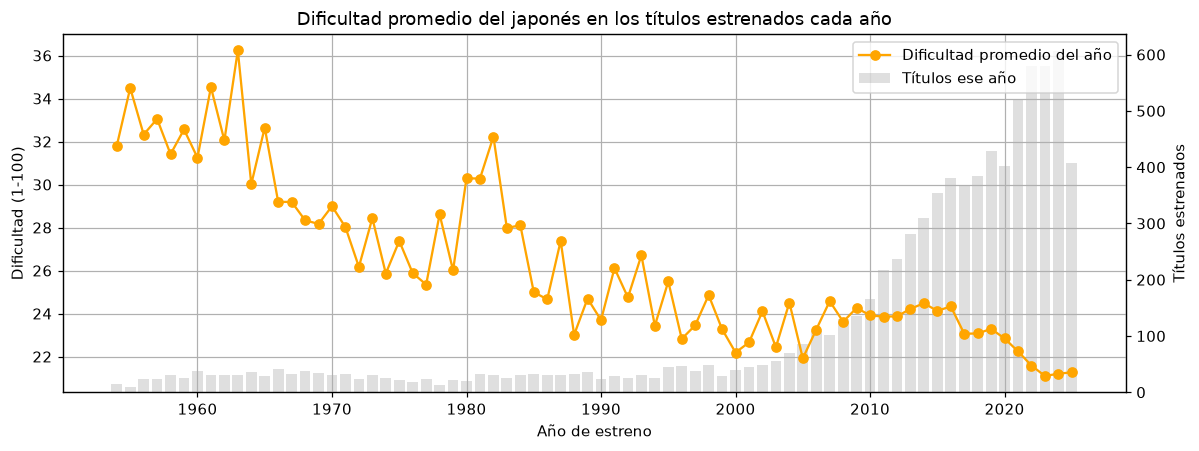

In [ ]:
# 1. Serie original: dificultad promedio por año + cuántos títulos la componen
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(df_ts['dificultad'], marker='o', color='orange', label='Dificultad promedio del año')
ax.set_title('Dificultad promedio del japonés en los títulos estrenados cada año')
ax.set_xlabel('Año de estreno'); ax.set_ylabel('Dificultad (1-100)'); ax.grid(True)
ax2 = ax.twinx()
ax2.bar(serie.index, serie['titulos'], color='gray', alpha=0.25, label='Títulos ese año')
ax2.set_ylabel('Títulos estrenados')
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right')
plt.tight_layout(); plt.savefig('figuras/0_serie.png'); plt.show()

**Qué se observa en la serie original:**
- **Tendencia descendente clara:** la dificultad promedio baja de unos **32-34 puntos en los años 50 y 60** a **21,1-21,3 en 2023-2025**. Cada vez se estrena japonés más accesible.
- **Tres etapas:** caída con mucho ruido (1954-2005), meseta muy estable cerca de **24 puntos (2008-2016)** y una nueva bajada desde 2017 hasta **21,1 en 2023**.
- **El ruido depende de cuántos títulos hay:** las barras grises muestran que antes de 2000 se estrenaban **unos 30 títulos al año** en el catálogo, y desde 2012 más de **400**. Con pocos títulos, un par de películas difíciles mueve todo el promedio; con cientos, el promedio es estable.
- **La mezcla de formatos influye:** el porcentaje de anime de cada año tiene correlación **−0,82** con la dificultad. Más anime en el año → promedio más fácil (en 2025 el 51% de los estrenos es anime).

## 1. Las tres gráficas pedidas

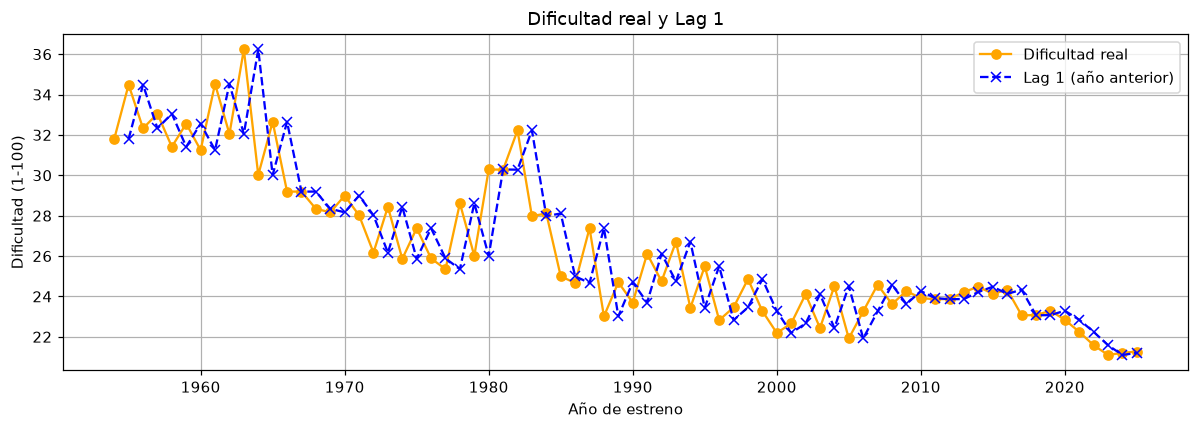

Correlación real vs lag_1: 0.85
Diferencia promedio entre un año y el anterior: 1.56 puntos
Años donde lag_1 más se equivoca:
anio
1964    6.22
1988    4.37
1980    4.28
1983    4.25
1963    4.19


In [ ]:
# 2. Dificultad real + Lag 1
plt.figure(figsize=(11, 4))
plt.plot(df_ts['dificultad'], marker='o', label='Dificultad real', color='orange')
plt.plot(df_ts['lag_1'], marker='x', linestyle='--', label='Lag 1 (año anterior)', color='blue')
plt.title('Dificultad real y Lag 1')
plt.xlabel('Año de estreno'); plt.ylabel('Dificultad (1-100)')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.savefig('figuras/1_lag1.png'); plt.show()

dif_lag = (df_ts['dificultad'] - df_ts['lag_1']).abs()
print(f"Correlación real vs lag_1: {df_ts['dificultad'].corr(df_ts['lag_1']):.2f}")
print(f"Diferencia promedio entre un año y el anterior: {dif_lag.mean():.2f} puntos")
print("Años donde lag_1 más se equivoca:")
print(dif_lag.sort_values(ascending=False).head(5).round(2).to_string())

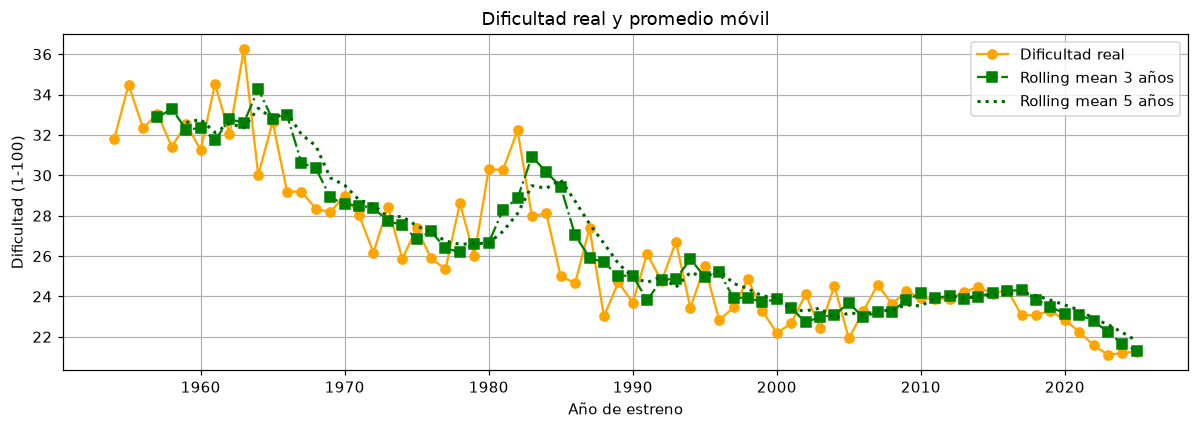

In [ ]:
# 3. Dificultad real + promedio móvil de 3 años (y de 5 años para comparar la ventana)
rm5 = df_ts['dificultad'].shift(1).rolling(5).mean()
plt.figure(figsize=(11, 4))
plt.plot(df_ts['dificultad'], marker='o', label='Dificultad real', color='orange')
plt.plot(df_ts['rolling_mean_3'], marker='s', linestyle='-.', label='Rolling mean 3 años', color='green')
plt.plot(rm5, linestyle=':', linewidth=2, label='Rolling mean 5 años', color='darkgreen')
plt.title('Dificultad real y promedio móvil')
plt.xlabel('Año de estreno'); plt.ylabel('Dificultad (1-100)')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.savefig('figuras/2_rolling_mean.png'); plt.show()

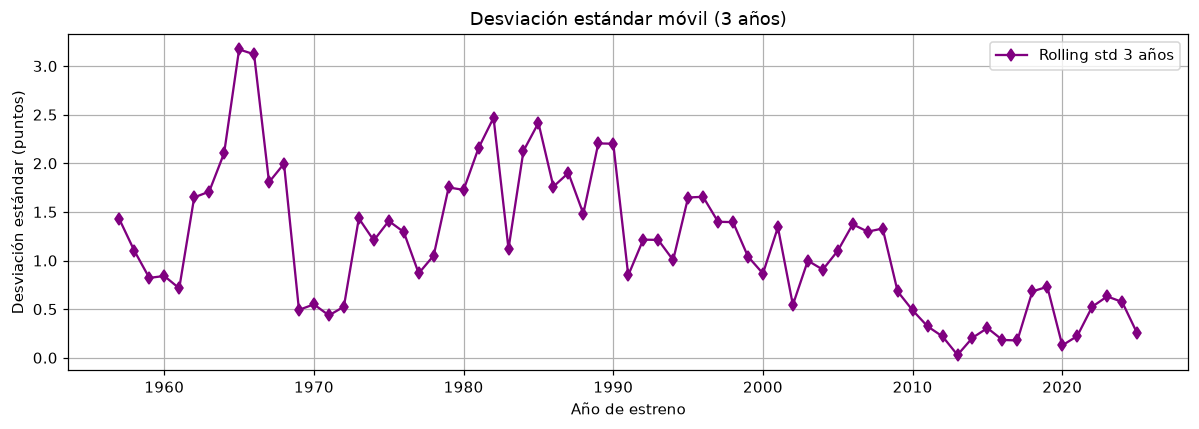

Años con más variabilidad:
anio
1965    3.17
1966    3.12
1982    2.47
1985    2.42
1989    2.20
1990    2.20

Promedio de rolling_std_3 por época, junto a cuántos títulos se estrenaban por año:
           rolling_std_3  titulos_por_anio
1954-1979           1.37             27.19
1980-1999           1.65             32.10
2000-2011           0.94            100.25
2012-2025           0.35            416.71


In [ ]:
# 4. Desviación estándar móvil (3 años)
plt.figure(figsize=(11, 4))
plt.plot(df_ts['rolling_std_3'], marker='d', linestyle='-', color='purple', label='Rolling std 3 años')
plt.title('Desviación estándar móvil (3 años)')
plt.xlabel('Año de estreno'); plt.ylabel('Desviación estándar (puntos)')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.savefig('figuras/3_rolling_std.png'); plt.show()

print("Años con más variabilidad:"); print(df_ts['rolling_std_3'].nlargest(6).round(2).to_string())
print("\nPromedio de rolling_std_3 por época, junto a cuántos títulos se estrenaban por año:")
epoca = pd.cut(df_ts.index, [1953, 1979, 1999, 2011, 2025], labels=['1954-1979', '1980-1999', '2000-2011', '2012-2025'])
print(pd.DataFrame({'rolling_std_3': df_ts['rolling_std_3'], 'titulos_por_anio': serie['titulos']})
      .groupby(epoca, observed=True).mean().round(2).to_string())

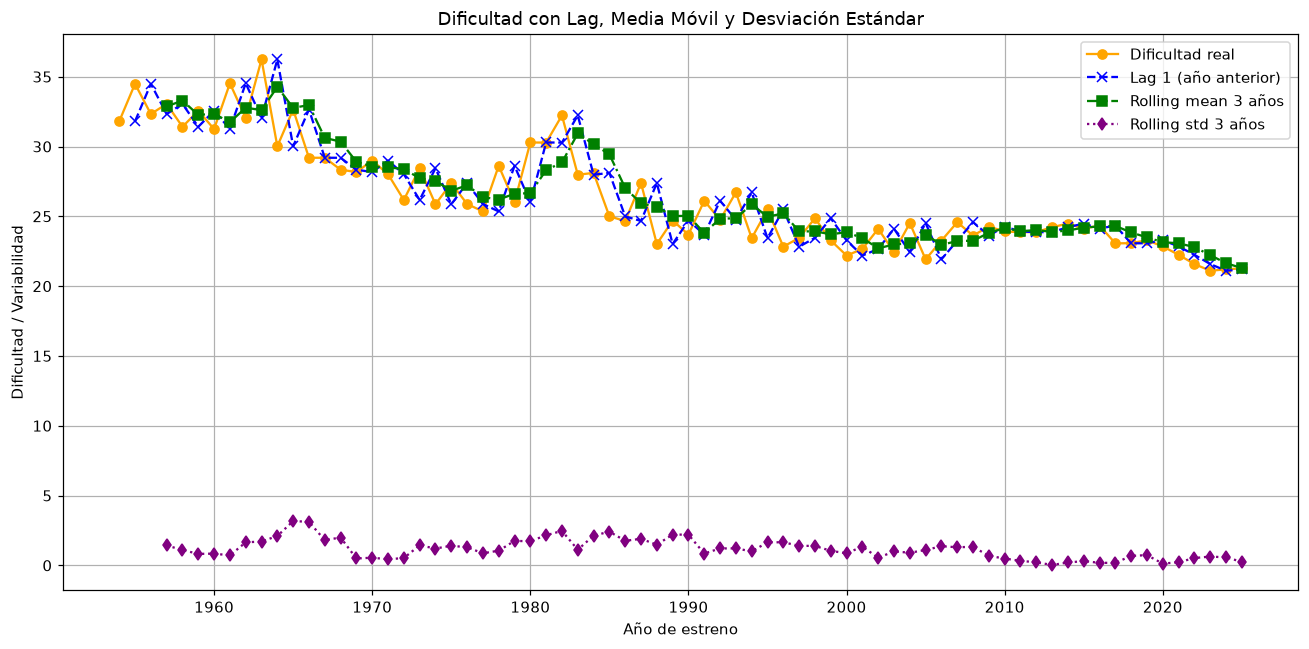

In [ ]:
# 5. Gráfica combinada
plt.figure(figsize=(12, 6))
plt.plot(df_ts['dificultad'], marker='o', label='Dificultad real', color='orange')
plt.plot(df_ts['lag_1'], marker='x', linestyle='--', label='Lag 1 (año anterior)', color='blue')
plt.plot(df_ts['rolling_mean_3'], marker='s', linestyle='-.', label='Rolling mean 3 años', color='green')
plt.plot(df_ts['rolling_std_3'], marker='d', linestyle=':', label='Rolling std 3 años', color='purple')
plt.title('Dificultad con Lag, Media Móvil y Desviación Estándar')
plt.xlabel('Año de estreno'); plt.ylabel('Dificultad / Variabilidad')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.savefig('figuras/4_combinada.png'); plt.show()

## 2 y 3. Análisis y respuestas

### A. Lag 1 (año anterior)

**¿Qué tan parecidos son los valores reales al lag_1?** Muy parecidos. La correlación entre la dificultad de un año y la del año anterior es **0,85**, y en promedio cambian **1,56 puntos** de un año a otro, en una serie que va de 21 a 36. Las dos líneas de la gráfica casi se superponen, con la de lag_1 corrida un año a la derecha.

**¿En qué parte del tiempo predice bien? ¿Dónde falla?**
- **Predice muy bien desde 2008:** con cientos de títulos por año, la dificultad cambia en promedio solo **0,36 puntos** de un año al siguiente. Usar "lo mismo que el año pasado" es casi exacto.
- **Falla antes de 1990**, en saltos bruscos: **1964** (de 36,2 a 30,0: error de 6,2 puntos), **1988** (4,4), **1980** (4,3), **1983** (4,3) y **1963** (4,2). En esos años lag_1 "se queda" en el valor anterior y llega tarde al cambio.

**¿Qué hipótesis podemos hacer cuando lag_1 no es útil?** Los fallos coinciden con años de **pocos estrenos (entre 20 y 40)**, donde unas pocas películas difíciles (por ejemplo, de época o con lenguaje formal) suben el promedio y al año siguiente desaparecen. Es decir, en esas épocas el valor de un año tiene **mucho ruido de muestra** y poca relación real con el anterior.

**¿Qué otros lags probaríamos y por qué?**
- **lag_2:** la autocorrelación con 2 años (**0,90**) es incluso mayor que con 1 año (0,85). La serie tiene un "zigzag" en el que un año alto suele seguir de uno bajo, y mirar 2 años atrás lo compensa.
- **lag_3 a lag_5:** las autocorrelaciones siguen altas (0,79 / 0,79 / 0,74) porque la tendencia es larga. Sirven para capturar la dirección de varios años seguidos.
- **No usaríamos lags estacionales (como lag_12 o lag_52):** con datos anuales no hay estacionalidad dentro del año que capturar.

### B. Promedio móvil de 3 años

**¿Qué patrón permite ver que no se nota en los datos reales?** La **tendencia de fondo y las etapas**. En los datos reales el zigzag de los años 60 a 90 esconde la caída; en el promedio móvil se ve una bajada casi continua de **34 a 24**, una meseta en **24 entre 2008 y 2016** y la nueva caída hasta **21,3**. También deja ver la "joroba" de **1980-1984**, cuando el promedio sube de 26,7 a 30,9 antes de volver a bajar.

**¿Dónde ayuda y dónde podría ocultar un cambio?**
- **Ayuda** en las épocas ruidosas (1954-2000), donde un año aislado como 1963 (36,2) se queda en **34,3** dentro del promedio y no confunde la tendencia.
- **Oculta o retrasa cambios reales:** la caída de **2016 a 2017** (de 24,3 a 23,1) es un cambio sostenido, pero el promedio móvil la muestra **2 a 3 años tarde** y sigue en 24,3 en 2017. Lo mismo pasa con el salto de **1980** (de 26,0 a 30,3), que el promedio absorbe poco a poco.

**¿Cambiaríamos la ventana?** Sí, depende de la época:
- **Para el periodo antiguo y ruidoso, 5 años** (línea punteada): con 20-40 títulos por año, 3 años siguen siendo pocos datos, y la ventana de 5 da una tendencia más limpia.
- **Para el periodo reciente, 3 años bastan** o incluso sobran: la serie ya es estable y una ventana larga solo añade retraso.
- En el modelo probamos ambas (rolling_mean_3 y rolling_mean_5), y la de 5 dio mejores resultados (sección de modelos).

### C. Desviación estándar móvil (3 años)

**¿Qué años muestran más variabilidad?** **1965-1966** (3,2 y 3,1 puntos), **1982** (2,5), **1985** (2,4) y **1989-1990** (2,2). La variabilidad mínima está en **2010-2016 y 2020-2021**, con valores entre **0,03 y 0,5**. Agrupando por épocas:

| Época | rolling_std_3 promedio | Títulos estrenados por año |
|---|---|---|
| 1954-1979 | 1,37 | 27 |
| 1980-1999 | 1,65 | 32 |
| 2000-2011 | 0,94 | 100 |
| 2012-2025 | 0,35 | 417 |

**¿Qué podrían indicar esos momentos de alta desviación en nuestro sector?**
- **Catálogos pequeños:** con pocos estrenos, la dificultad del año depende de qué títulos concretos salieron. Más que un cambio en "el japonés de la época", la desviación alta refleja **poca información**.
- **Cambios en la mezcla de formatos:** a partir de 1979 empieza a entrar el anime en el catálogo (antes casi todo era cine live-action). Esa mezcla cambiante entre formatos mucho más fáciles y mucho más difíciles hace saltar el promedio.
- En la era reciente, un pico pequeño como el de **2018-2019 (0,7)** marca el inicio de la nueva bajada de dificultad: ahí la variabilidad avisa de un cambio de tendencia.

**¿Cómo influye en un modelo predictivo?** El modelo aprende del pasado. Si se entrena con años muy variables (1954-2000) y se prueba en años muy estables (2012-2025), **espera saltos que ya no ocurren** y predice movimientos de más. Eso es exactamente lo que vimos con XGBoost y KNN en la sección de modelos. Además, la desviación alta indica que el valor real es en parte ruido, así que ningún modelo puede acertarlo bien.

**¿Qué haríamos si supiéramos que el próximo año tiene alta desviación?**
- **Confiar más en el promedio de varios años** (rolling_mean_5) que en el último valor, y mostrar la predicción **como un rango** y no como un número exacto.
- En Yomi Level: **no reclasificar el catálogo** por un solo año raro, y mandar a revisión humana los títulos nuevos de esas épocas, igual que la "zona gris" de la app.

### 4 y 5. ¿Qué variables usaríamos y qué tan estable es nuestra serie?

**¿Cuál de las tres usaríamos?** Las tres, cada una con un papel distinto:
- **lag_1, la principal:** es la más informativa. "Igual que el año anterior" ya acierta con un error de solo **0,36 puntos** en 2012-2025, y ningún modelo lo superó.
- **rolling_mean (mejor de 5 años que de 3):** da la tendencia y corrige los saltos sueltos de la época antigua.
- **rolling_std:** no da dirección, pero dice **cuánto confiar** en la predicción y explica por qué el modelo se equivoca más antes del 2000.

**¿Qué lags o rolling adicionales serían útiles en nuestro sector?**
- **lag_2**, por su autocorrelación de 0,90.
- **rolling_mean_5 y rolling_std_5**, por el ruido de los años con pocos títulos.
- **rolling_mean_10**, para ver tendencias de "generación" del contenido (décadas).
- **Variables externas del mismo año:** el **% de anime** (correlación −0,82 con la dificultad) y el **número de títulos** como medida de confianza.

**¿Nuestra serie es estable o variable?** Las dos cosas, según la época:
- **No es estacionaria:** tiene una **tendencia descendente de unos 12 puntos en 70 años**.
- **Su variabilidad bajó con el tiempo:** la desviación móvil pasó de **1,4-1,7** (antes del 2000) a **0,35** (2012-2025).

Lo sabemos por las gráficas (el promedio móvil cae, la desviación se aplana) y por los números: el cambio medio entre años pasó de **2 puntos** a **0,36**. Hoy es una serie **estable con tendencia a la baja**.

### 6. Hoja de justificación de variables temporales

**Sector:** aprendizaje de japonés con contenido audiovisual · **Variable objetivo:** dificultad promedio anual de los estrenos (1-100) · **Frecuencia:** anual (el dataset solo trae el año de estreno) · **Periodo:** 1954-2025.

| Variable | ¿Qué mira en nuestro caso? | ¿La usamos? | Justificación con nuestros datos |
|---|---|---|---|
| `lag_1` | Dificultad promedio del año anterior | Sí, principal | Correlación 0,85; error medio de 0,36 puntos desde 2012. La industria cambia despacio. |
| `lag_2` | Dificultad de hace 2 años | Sí | Autocorrelación 0,90, mayor que la de lag_1; compensa el zigzag de las épocas ruidosas. |
| `lag_3` a `lag_5` | Valores de 3 a 5 años atrás | Opcional | Autocorrelación 0,74-0,79 por la tendencia larga; aportan poco que no den el rolling. |
| `rolling_mean_3` | Promedio de los 3 años anteriores | Sí (pedido) | Muestra la tendencia, pero con 20-40 títulos por año aún es ruidosa y llega 2-3 años tarde a los cambios. |
| `rolling_mean_5` | Promedio de los 5 años anteriores | Sí, preferida | Suaviza mejor la época antigua y mejoró a Regresión Lineal, Random Forest y SVM. |
| `rolling_std_3` / `rolling_std_5` | Variabilidad reciente | Sí | Mide la confianza: alta antes de 2000 (pocos títulos), mínima en 2010-2016. |
| `% anime del año` | Mezcla de formatos estrenados | Recomendada (externa) | Correlación −0,82 con la dificultad: explica buena parte de la bajada. |
| `títulos del año` | Tamaño de la muestra | Recomendada (peso) | Con más títulos el promedio es más confiable; sirve para ponderar años. |
| Lags estacionales (`lag_12`, `lag_52`) | Mismo periodo del año anterior | No | Con datos anuales no hay estacionalidad dentro del año. |

## 7. Modelos supervisados sobre la serie

Usamos los 5 modelos de clase (Regresión Lineal, Random Forest, XGBoost, SVM y KNN) con la misma división que el ejemplo: **80% de los años para entrenar y 20% para probar, sin mezclar el orden**. Entrenamos con **1957-2011 (55 años)** y probamos con **2012-2025 (14 años)**.

Agregamos una referencia que no está en el ejemplo: el **modelo ingenuo**, que predice "lo mismo que el año anterior" (es decir, usar lag_1 tal cual). Un modelo solo vale la pena si le gana a eso.

Probamos tres versiones:
1. **V1, como en clase:** el modelo predice directamente la dificultad del año con `lag_1`, `rolling_mean_3` y `rolling_std_3`.
2. **V2, diferenciación:** el modelo predice **cuánto cambia** la dificultad respecto al año anterior, con las mismas variables expresadas respecto a lag_1.
3. **V3, conjunto propuesto:** igual que V2, pero con `lag_2`, `rolling_mean_5` y `rolling_std_5`.

In [ ]:
# ----------------------------------------
# 🎯 VARIABLES Y DIVISIÓN (sin mezclar el orden del tiempo)
# ----------------------------------------
datos = df_ts.dropna()
features = ['lag_1', 'rolling_mean_3', 'rolling_std_3']
X, y = datos[features], datos['dificultad']
corte = int(len(datos) * 0.8)
X_train, X_test, y_train, y_test = X.iloc[:corte], X.iloc[corte:], y.iloc[:corte], y.iloc[corte:]
print(f"Entrenamiento: {X_train.index.min()}–{X_train.index.max()} ({len(X_train)} años) | "
      f"Prueba: {X_test.index.min()}–{X_test.index.max()} ({len(X_test)} años)")
print(f"Rango de dificultad en entrenamiento: {y_train.min():.1f} a {y_train.max():.1f} | en prueba: {y_test.min():.1f} a {y_test.max():.1f}")

def modelos():
    return {
        "Regresión Lineal": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
        "XGBoost": XGBRegressor(objective='reg:squarederror', n_estimators=25, random_state=42, verbosity=0),
        "SVM": SVR(),
        "KNN": KNeighborsRegressor(n_neighbors=5)
    }

def entrenar(X_tr, y_tr, X_te):
    """Entrena los 5 modelos; SVM y KNN con datos escalados, como en clase."""
    sc = StandardScaler().fit(X_tr)
    pred = {}
    for nombre, modelo in modelos().items():
        if nombre in ["SVM", "KNN"]:
            pred[nombre] = modelo.fit(sc.transform(X_tr), y_tr).predict(sc.transform(X_te))
        else:
            pred[nombre] = modelo.fit(X_tr, y_tr).predict(X_te)
    return pred

def tabla(pred, real):
    return pd.DataFrame({k: {"MSE": mean_squared_error(real, v), "R2": r2_score(real, v),
                             "MAE (puntos)": mean_absolute_error(real, v)} for k, v in pred.items()}).T.round(2)

# Versión 1: como en clase, el modelo predice directamente el nivel de dificultad
pred_nivel = entrenar(X_train, y_train, X_test)
pred_nivel_tabla = dict(pred_nivel, **{"Ingenuo (= año anterior)": X_test['lag_1'].values})
tabla(pred_nivel_tabla, y_test)

Entrenamiento: 1957–2011 (55 años) | Prueba: 2012–2025 (14 años)
Rango de dificultad en entrenamiento: 21.9 a 36.2 | en prueba: 21.1 a 24.5


,MSE,R2,MAE (puntos)
Regresión Lineal,1.06,0.26,0.87
Random Forest,2.65,-0.86,1.29
XGBoost,3.20,-1.25,1.44
SVM,5.21,-2.67,1.92
KNN,3.16,-1.22,1.42
Ingenuo (= año anterior),0.23,0.84,0.36


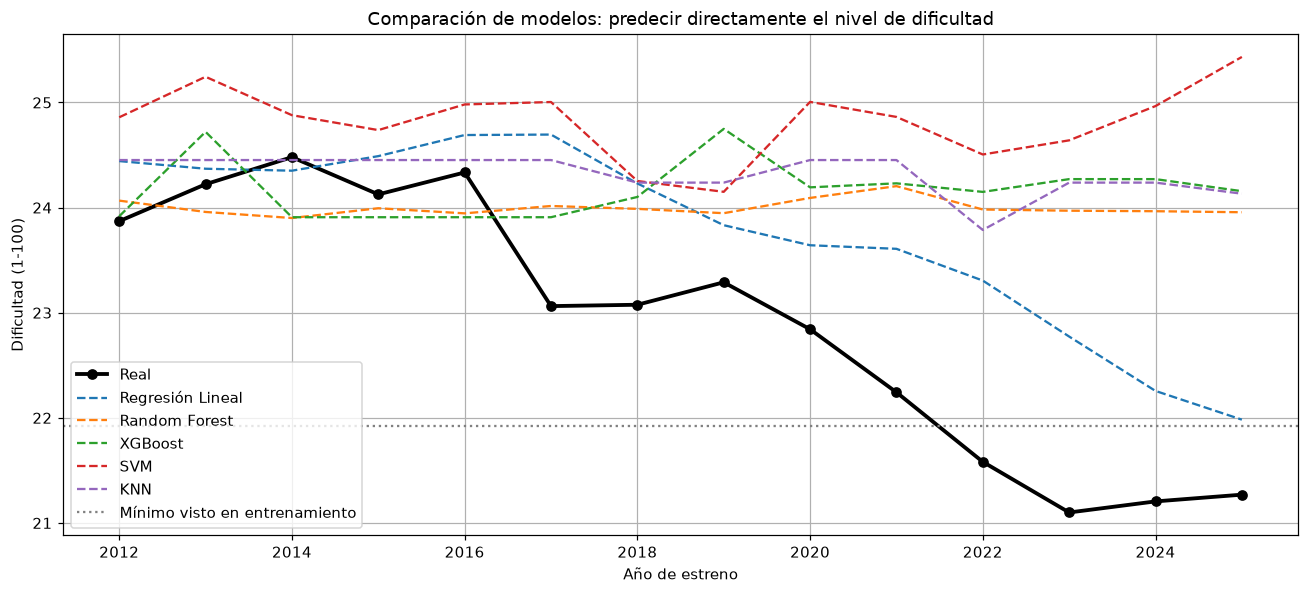

In [ ]:
# 📈 GRÁFICA COMPARATIVA (versión 1: predecir el nivel)
plt.figure(figsize=(12, 5.5))
plt.plot(y_test.index, y_test.values, label='Real', linewidth=2.5, color='black', marker='o')
for nombre, p in pred_nivel.items():
    plt.plot(y_test.index, p, linestyle='--', label=nombre)
plt.axhline(y_train.min(), color='gray', linestyle=':', label='Mínimo visto en entrenamiento')
plt.title('Comparación de modelos: predecir directamente el nivel de dificultad')
plt.xlabel('Año de estreno'); plt.ylabel('Dificultad (1-100)')
plt.legend(); plt.grid(True); plt.tight_layout(); plt.savefig('figuras/5_comparativa_nivel.png'); plt.show()

**Qué pasa al predecir el nivel directamente (V1):**
- Todos los modelos se quedan **arriba de la línea real** desde 2017, y **ninguno le gana al ingenuo** (R² 0,84). Random Forest, XGBoost, SVM y KNN tienen incluso **R² negativo**: predicen peor que el promedio.
- **El problema es la tendencia.** Entre 2022 y 2025 la dificultad real (21,1-21,6) baja del **mínimo que los modelos vieron en entrenamiento (21,9)**, la línea gris punteada. Random Forest, XGBoost y KNN solo pueden repetir valores que ya vieron, así que se quedan "pegados" en unos 24 puntos.
- La **Regresión Lineal** es la única que sigue la bajada, porque una recta sí puede extrapolar; aun así va unos 2 años atrasada.
- **SVM** con parámetros por defecto se queda cerca del promedio histórico (unos 25): no se ajusta a la escala de esta serie.

Esto coincide con la tabla de la clase: Random Forest y los árboles tienen "poca extrapolación fuera de rango".

In [ ]:
# Versión 2: el modelo predice el CAMBIO respecto al año anterior (diferenciación)
# Las variables se expresan relativas al último valor conocido, así no dependen del nivel.
def relativas(d):
    r = pd.DataFrame(index=d.index)
    r['rm3_menos_lag1'] = d['rolling_mean_3'] - d['lag_1']
    r['rolling_std_3'] = d['rolling_std_3']
    return r

Xr = relativas(datos)
cambio = datos['dificultad'] - datos['lag_1']
pred_cambio = {k: X_test['lag_1'].values + v
               for k, v in entrenar(Xr.iloc[:corte], cambio.iloc[:corte], Xr.iloc[corte:]).items()}
pred_cambio_tabla = dict(pred_cambio, **{"Ingenuo (= año anterior)": X_test['lag_1'].values})
tabla(pred_cambio_tabla, y_test)

,MSE,R2,MAE (puntos)
Regresión Lineal,0.70,0.51,0.68
Random Forest,0.91,0.36,0.76
XGBoost,1.01,0.29,0.81
SVM,0.45,0.69,0.56
KNN,0.44,0.69,0.53
Ingenuo (= año anterior),0.23,0.84,0.36


In [ ]:
# Versión 3: conjunto propuesto para el sector (lag_2 + ventana de 5 años), también prediciendo el cambio
p = df_ts['dificultad'].shift(1)
extra = pd.DataFrame({'lag_2': df_ts['dificultad'].shift(2),
                      'rolling_mean_5': p.rolling(5).mean(), 'rolling_std_5': p.rolling(5).std()})
datos5 = df_ts[['dificultad', 'lag_1']].join(extra).dropna()
X5 = pd.DataFrame({'lag2_menos_lag1': datos5['lag_2'] - datos5['lag_1'],
                   'rm5_menos_lag1': datos5['rolling_mean_5'] - datos5['lag_1'],
                   'rolling_std_5': datos5['rolling_std_5']})
c5 = int(len(datos5) * 0.8)
cambio5 = datos5['dificultad'] - datos5['lag_1']
base5, real5 = datos5['lag_1'].iloc[c5:].values, datos5['dificultad'].iloc[c5:]
pred_v3 = {k: base5 + v for k, v in entrenar(X5.iloc[:c5], cambio5.iloc[:c5], X5.iloc[c5:]).items()}
print(f"Prueba: {real5.index.min()}–{real5.index.max()} (los mismos años que las versiones 1 y 2)")
tabla(dict(pred_v3, **{"Ingenuo (= año anterior)": base5}), real5)

Prueba: 2012–2025 (los mismos años que las versiones 1 y 2)


,MSE,R2,MAE (puntos)
Regresión Lineal,0.62,0.56,0.60
Random Forest,0.65,0.54,0.56
XGBoost,2.15,-0.51,1.31
SVM,0.31,0.78,0.50
KNN,0.82,0.43,0.74
Ingenuo (= año anterior),0.23,0.84,0.36


In [ ]:
# 📋 Resumen: R² de cada modelo en las tres versiones (mismos 14 años de prueba)
resumen = pd.DataFrame({
    'V1 nivel (lag_1, rm3, rs3)': tabla(pred_nivel_tabla, y_test)['R2'],
    'V2 cambio (lag_1, rm3, rs3)': tabla(pred_cambio_tabla, y_test)['R2'],
    'V3 cambio (lag_1, lag_2, rm5, rs5)': tabla(dict(pred_v3, **{"Ingenuo (= año anterior)": base5}), real5)['R2']})
resumen

,"V1 nivel (lag_1, rm3, rs3)","V2 cambio (lag_1, rm3, rs3)","V3 cambio (lag_1, lag_2, rm5, rs5)"
Regresión Lineal,0.26,0.51,0.56
Random Forest,-0.86,0.36,0.54
XGBoost,-1.25,0.29,-0.51
SVM,-2.67,0.69,0.78
KNN,-1.22,0.69,0.43
Ingenuo (= año anterior),0.84,0.84,0.84


In [ ]:
# ⚠️ Comprobación: ¿qué pasa si el rolling incluye el año que se predice (código de clase sin shift)?
fuga = pd.DataFrame({'lag_1': df_ts['lag_1'],
                     'rolling_mean_3': df_ts['dificultad'].rolling(3).mean(),
                     'rolling_std_3': df_ts['dificultad'].rolling(3).std(),
                     'dificultad': df_ts['dificultad']}).dropna()
cf = int(len(fuga) * 0.8)
pf = entrenar(fuga[features].iloc[:cf], fuga['dificultad'].iloc[:cf], fuga[features].iloc[cf:])
print("R² con fuga de datos (NO válido):")
print(tabla(pf, fuga['dificultad'].iloc[cf:])['R2'].to_string())

R² con fuga de datos (NO válido):
Regresión Lineal    0.87
Random Forest       0.28
XGBoost             0.42
SVM                -2.00
KNN                -0.34


**Diferenciación y comparación de versiones:**
- **Predecir el cambio (V2 y V3) mejora a todos los modelos.** Random Forest pasa de R² **−0,86 a 0,54**, KNN de −1,22 a 0,69 y SVM de −2,67 a **0,78**. Al predecir "cuánto sube o baja" en vez del valor exacto, ya no importa que los años nuevos estén fuera del rango de entrenamiento. Es la "diferenciación para eliminar tendencia" que vimos en la descomposición de la serie.
- **El conjunto propuesto (V3: lag_2 + ventana de 5 años)** mejora a Regresión Lineal (0,51 → 0,56), Random Forest (0,36 → 0,54) y SVM (0,69 → 0,78) frente a V2.
- **Aun así, ninguno le gana al ingenuo (R² 0,84).** En 2012-2025 la serie cambia tan poco (0,36 puntos por año) que repetir el año anterior es casi imbatible.

**Comprobación de fuga de datos:** si se calcula el rolling **incluyendo el año que se quiere predecir** (como en el código del ejemplo, `rolling(3)` sin `shift`), la Regresión Lineal sube a **R² 0,87** y parece ganarle al ingenuo. Pero ese resultado es falso: el modelo está viendo parte de la respuesta. Por eso en todo el taller los rolling usan solo años anteriores, que es como los define la teoría ("promedio de las 3 semanas **anteriores**").

### Gráficas por modelo

Cada gráfica muestra la dificultad real (negro), la predicción directa del nivel (V1, línea clara punteada) y la predicción del cambio con el conjunto propuesto (V3, línea con cuadrados).

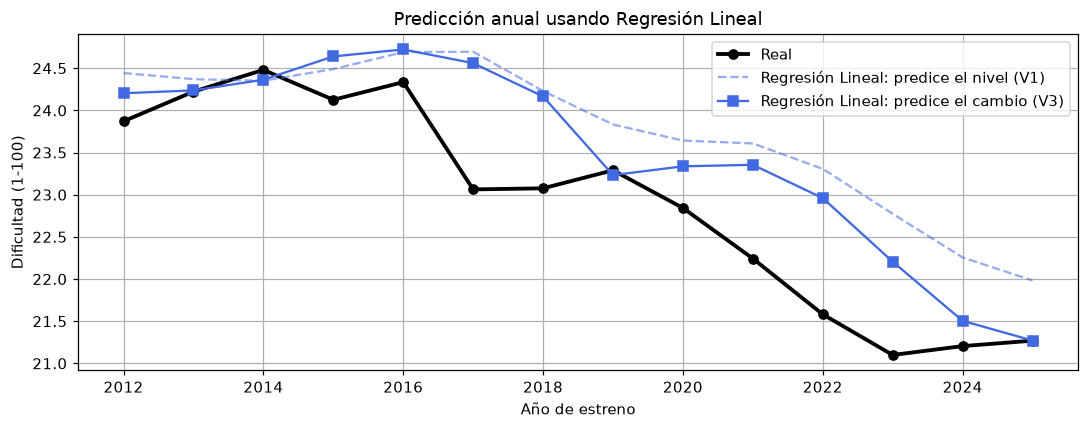

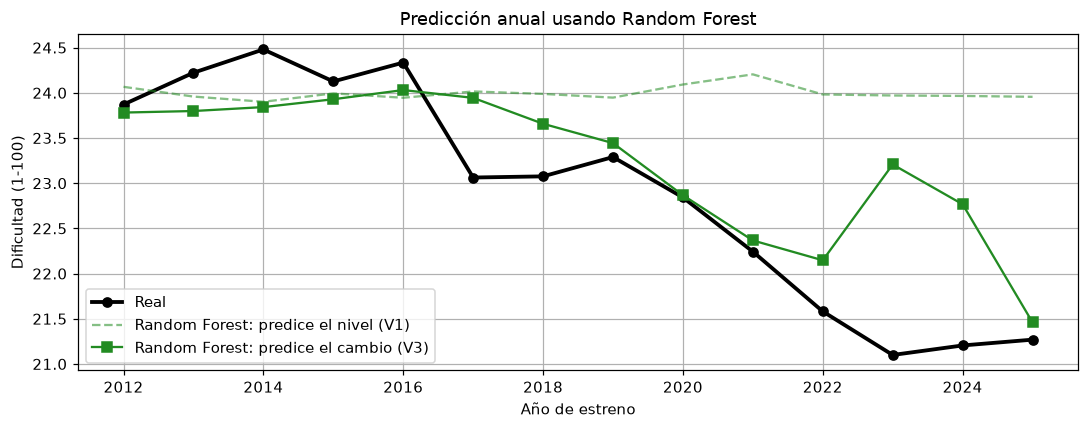

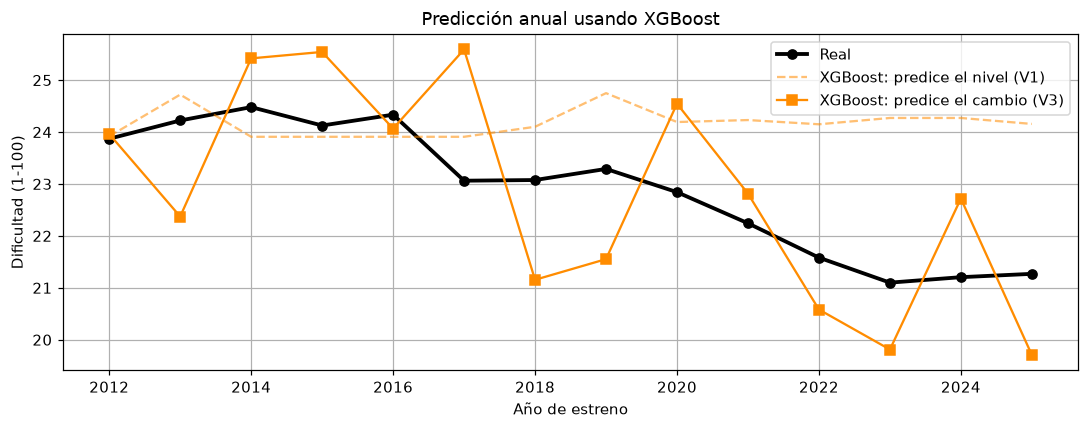

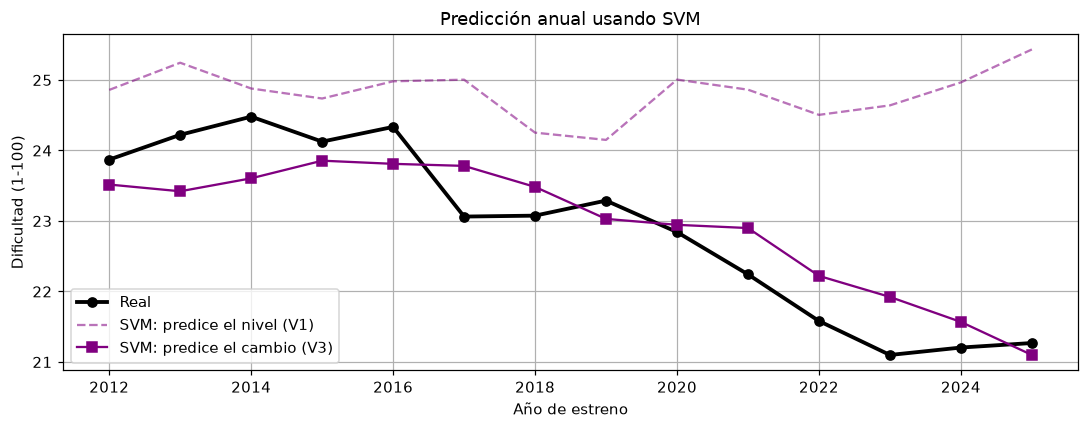

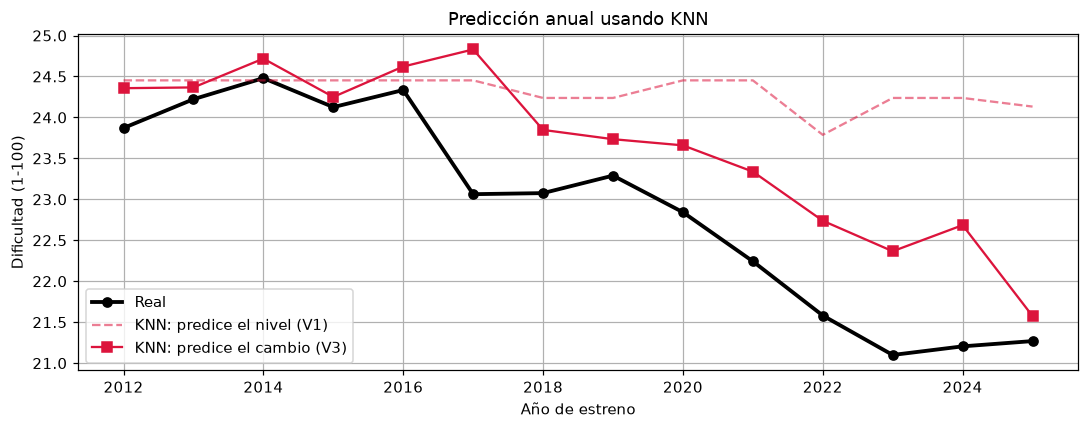

In [ ]:
# 📈 Una gráfica por modelo: real vs. predicción directa del nivel (V1) y predicción del cambio (V3)
colores = {"Regresión Lineal": 'royalblue', "Random Forest": 'forestgreen',
           "XGBoost": 'darkorange', "SVM": 'purple', "KNN": 'crimson'}
for i, (nombre, color) in enumerate(colores.items()):
    plt.figure(figsize=(10, 4))
    plt.plot(y_test.index, y_test.values, label='Real', linewidth=2.5, color='black', marker='o')
    plt.plot(y_test.index, pred_nivel[nombre], linestyle='--', color=color, alpha=0.55,
             label=f'{nombre}: predice el nivel (V1)')
    plt.plot(real5.index, pred_v3[nombre], linestyle='-', marker='s', color=color,
             label=f'{nombre}: predice el cambio (V3)')
    plt.title(f'Predicción anual usando {nombre}')
    plt.xlabel('Año de estreno'); plt.ylabel('Dificultad (1-100)')
    plt.grid(True); plt.legend(); plt.tight_layout()
    plt.savefig(f'figuras/6_{i}_{nombre.split()[0].lower()}.png'); plt.show()

### Hallazgos por modelo

**Regresión Lineal**
- *Dónde acierta:* 2012-2016, cuando la serie está estable cerca de 24, y es el único modelo que en V1 baja junto con la tendencia.
- *Dónde falla:* la caída de 2017 la ve con unos **2 años de retraso**, porque se apoya en el promedio de años anteriores, que todavía estaban altos.
- *Variables que lo explicarían:* el rolling_mean "jala" la predicción hacia el pasado. Con datos más estables, darle más peso a lag_1 o agregar el % de anime del año reduciría el retraso.

**Random Forest**
- *Dónde acierta:* en V3 sigue bien la bajada de **2019 a 2022** (error menor a 0,6 puntos).
- *Dónde falla:* en V1 se queda **plano en 24** todo el periodo, porque no puede predecir valores que no vio. En V3 sobrestima **2023 y 2024** (predice 23,2 y 22,8 cuando la realidad fue 21,1 y 21,2): espera un rebote porque en el pasado, después de una bajada, solía venir una subida.
- *Variables que lo explicarían:* las de diferencias (cambio respecto a lag_1). Más años de la era estable le ayudarían a no esperar rebotes.

**XGBoost**
- *Dónde acierta:* en algunos años sueltos (2012 y 2016) queda a menos de 0,3 puntos.
- *Dónde falla:* en V3 es el más errático. Oscila entre **22,4 y 25,6** en 2013-2017 y entre **19,7 y 22,7** en 2023-2025, exagerando los movimientos. Con pocos años de entrenamiento (53) **memoriza el ruido** de la época antigua, cuando eran normales saltos de 3-6 puntos. Es el único que empeora al pasar de V2 a V3 (R² 0,29 → −0,51).
- *Variables que lo explicarían:* tiene muy pocos datos para tantos árboles. Necesitaría más regularización (menos profundidad, tasa de aprendizaje menor) o entrenar solo con los años de catálogo grande.

**SVM**
- *Dónde acierta:* en V3 es el **mejor de los 5 modelos (R² 0,78, error medio de 0,50 puntos)**. Sigue la tendencia de forma suave, sin exagerar picos, justo lo que necesita una serie que hoy es estable.
- *Dónde falla:* en V1, con la escala original, se queda en unos 25 todo el tiempo. En V3 subestima levemente **2012-2016** (entre 0,3 y 0,9 puntos abajo).
- *Variables que lo explicarían:* el SVM depende mucho de la escala. Funciona cuando las variables se expresan como cambios pequeños alrededor de cero (V3), no como niveles.

**KNN**
- *Dónde acierta:* 2012-2016, cuando los "vecinos" del pasado se parecen a la situación actual.
- *Dónde falla:* desde 2017 va siempre **por encima** de la realidad, entre 0,3 y 1,8 puntos. Promedia los 5 casos más parecidos del pasado, y en el pasado una bajada solía corregirse con una subida.
- *Variables que lo explicarían:* KNN no puede generalizar a una situación que no ha visto: una bajada **sostenida** de 8 años seguidos casi no existe en el entrenamiento.

### Tabla resumen (R² en 2012-2025)

| Modelo | V1: nivel | V2: cambio | V3: cambio + lag_2 + ventana 5 |
|---|---|---|---|
| Ingenuo (año anterior) | 0,84 | 0,84 | 0,84 |
| Regresión Lineal | 0,26 | 0,51 | 0,56 |
| Random Forest | −0,86 | 0,36 | 0,54 |
| XGBoost | −1,25 | 0,29 | −0,51 |
| SVM | −2,67 | 0,69 | **0,78** |
| KNN | −1,22 | 0,69 | 0,43 |

## Conclusiones

1. **La dificultad del japonés en el contenido audiovisual baja con los años:** de unos 33 puntos en los años 50 a 21 en 2025. Para Yomi Level es una buena noticia: cada año hay más material accesible para principiantes, sobre todo por el crecimiento del anime en el catálogo.
2. **lag_1 es la variable más útil.** Nuestra serie anual es muy persistente: "igual que el año pasado" se equivoca solo 0,36 puntos en promedio desde 2012, y ninguno de los 5 modelos lo superó.
3. **La variabilidad de la serie es sobre todo ruido de muestra.** La desviación móvil es alta cuando se estrenaban unos 30 títulos al año y casi cero cuando se estrenan más de 400. rolling_std sirve para saber **cuánto confiar** en la predicción.
4. **Con tendencia, conviene predecir el cambio y no el nivel.** Los árboles y KNN no pueden extrapolar por debajo del mínimo que vieron. Diferenciar la serie los lleva de R² negativo a positivo, y con **lag_2 y una ventana de 5 años** el mejor modelo fue **SVM (R² 0,78)**.
5. **Hay que calcular los rolling solo con el pasado.** Si el promedio incluye el año que se predice, la Regresión Lineal parece llegar a R² 0,87, pero es fuga de datos: la misma lección que aplicamos en el proyecto al excluir las columnas de dificultad de kanji y vocabulario.

**Variables que usaríamos:** `lag_1` + `lag_2` + `rolling_mean_5` + `rolling_std_5`, prediciendo el **cambio** respecto al año anterior. Como mejora, agregaríamos el **% de anime del año** como variable externa y el **número de títulos** como peso.

**Limitación:** el dataset solo trae el año de estreno, así que la serie es anual (72 puntos) y no semanal. Con fechas exactas de estreno se podría trabajar por temporadas de anime (invierno, primavera, verano y otoño), que es como se organiza la industria.